# Expense Tracker — Exploratory Data Analysis
Step-by-step EDA on the synthetic expense dataset. Run `python main.py` first so the data files exist.

In [1]:
import sys, os
sys.path.append(os.path.abspath('..'))  # so we can import src/
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import analysis, config
from src.cleaning import clean_expenses, add_features
sns.set_theme(style='whitegrid')
%matplotlib inline

## 1. Load raw data and inspect quality

In [2]:
raw = pd.read_csv('../data/raw/expenses_raw.csv')
print(raw.shape)
raw.head(10)

(943, 6)


,transaction_id,date,category,description,amount,payment_method
0,TXN100000,2025-02-03,Food,Swiggy order,278.54,UPI
1,TXN100001,2025-04-11,Food,Lunch,71.48,UPI
2,TXN100002,2025-11-23,Entertainment,Netflix,1481.7,UPI
3,TXN100003,2025-01-12,Food,Cafe,338.01,UPI
4,TXN100004,2025-01-15,Transport,Ola,136.89,Credit Card
5,TXN100005,2025-04-17,Food,Street food,532.89,UPI
6,TXN100006,2025-08-22,Food,Zomato order,312.37,Cash
7,TXN100007,2025-04-10,Food,Street food,205.34,Cash
8,TXN100008,2025-05-10,Food,Dinner out,NaN,Debit Card
9,TXN100009,2025-05-07,Transport,Metro card,147.15,UPI


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 943 entries, 0 to 942
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   transaction_id  943 non-null    str  
 1   date            943 non-null    str  
 2   category        943 non-null    str  
 3   description     925 non-null    str  
 4   amount          935 non-null    str  
 5   payment_method  915 non-null    str  
dtypes: str(6)
memory usage: 86.4 KB


In [4]:
# Missing values per column
raw.isna().sum()

transaction_id     0
date               0
category           0
description       18
amount             8
payment_method    28
dtype: int64

In [5]:
# Inconsistent category labels BEFORE cleaning
raw['category'].value_counts()

category
Food               374
Transport          242
Groceries           85
Shopping            58
Entertainment       50
Utilities           35
food                22
Health              19
Rent                12
Travel              11
transport           11
Education            9
utilities            5
entertainment        3
groceries            3
health               3
shopping             1
Name: count, dtype: int64

In [6]:
# Duplicates (ignoring the id column)
raw.drop(columns='transaction_id').duplicated().sum()

np.int64(15)

## 2. Clean + feature engineering

In [7]:
clean, report = clean_expenses(raw)
df = add_features(clean)
df.head()

Cleaning report:
  rows_before                 : 943
  duplicates_removed          : 15
  unparseable_dates_dropped   : 0
  missing_amount_dropped      : 8
  negative_amounts_fixed      : 6
  missing_payment_filled      : 27
  missing_description_filled  : 18
  invalid_category_dropped    : 0
  rows_after                  : 920


,transaction_id,date,category,description,amount,payment_method,year,month,month_name,year_month,day,weekday,is_weekend,week_of_year,quarter,expense_type,amount_bucket
0,TXN100292,2025-01-01,Rent,Monthly rent,15000.00,Net Banking,2025,1,Jan,2025-01,1,Wednesday,False,1,Q1,Essential,Very large (5k+)
1,TXN100861,2025-01-01,Transport,Auto,27.95,Credit Card,2025,1,Jan,2025-01,1,Wednesday,False,1,Q1,Essential,Small (<200)
2,TXN100195,2025-01-01,Transport,Uber,392.37,UPI,2025,1,Jan,2025-01,1,Wednesday,False,1,Q1,Essential,Medium (200-1k)
3,TXN100449,2025-01-02,Transport,Uber,62.76,Unknown,2025,1,Jan,2025-01,2,Thursday,False,1,Q1,Essential,Small (<200)
4,TXN100786,2025-01-03,Groceries,Blinkit,735.59,UPI,2025,1,Jan,2025-01,3,Friday,False,1,Q1,Essential,Medium (200-1k)


In [8]:
df.describe()

,date,amount,year,month,day,week_of_year
count,920,920.000000,920.0,920.000000,920.000000,920.000000
mean,2025-07-06 09:15:39.130434,791.671337,2025.0,6.672826,15.586957,27.239130
min,2025-01-01 00:00:00,13.910000,2025.0,1.000000,1.000000,1.000000
25%,2025-03-28 00:00:00,160.080000,2025.0,3.000000,8.000000,13.000000
50%,2025-07-07 00:00:00,295.790000,2025.0,7.000000,16.000000,27.500000
75%,2025-10-17 00:00:00,724.137500,2025.0,10.000000,23.000000,42.000000
max,2025-12-31 00:00:00,15000.000000,2025.0,12.000000,31.000000,52.000000
std,NaN,1842.296084,0.0,3.626243,8.832564,15.750067


## 3. Category analysis

In [9]:
analysis.category_summary(df)

,total,average,transactions,largest,share_pct
category,,,,,
Rent,180000.00,15000.00,12,15000.00,24.71
Food,120853.57,313.09,386,2212.56,16.59
Shopping,112379.65,1971.57,57,9474.97,15.43
Groceries,112271.23,1290.47,87,2995.37,15.41
Utilities,54339.74,1358.49,40,3361.19,7.46
Transport,44381.20,180.41,246,902.90,6.09
Entertainment,43255.87,831.84,52,3113.58,5.94
Travel,30423.36,2765.76,11,8887.30,4.18
Health,16197.12,809.86,20,2263.14,2.22


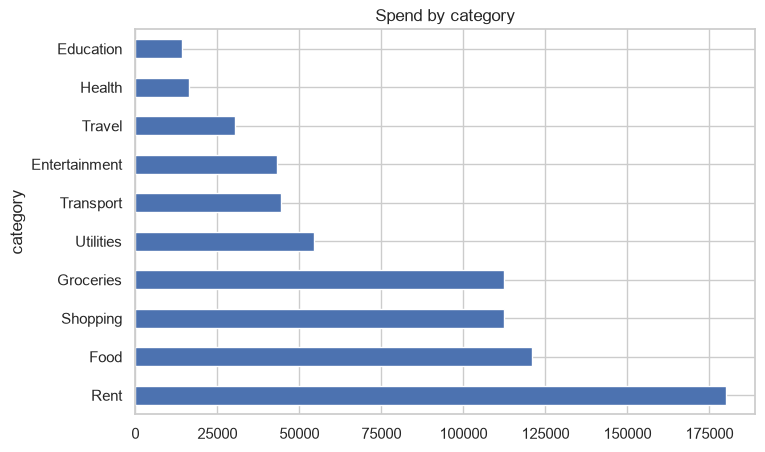

In [10]:
analysis.category_summary(df)['total'].plot(kind='barh', figsize=(8,5), title='Spend by category'); plt.show()

## 4. Monthly trend

In [11]:
m = analysis.monthly_trend(df)
m

,total,transactions,mom_change_pct,rolling_3m_avg,savings,savings_rate_pct
year_month,,,,,,
2025-01,54660.60,85,NaN,54660.60,20339.40,27.12
2025-02,66811.25,80,22.23,60735.92,8188.75,10.92
2025-03,49280.31,74,-26.24,56917.39,25719.69,34.29
2025-04,49986.87,66,1.43,55359.48,25013.13,33.35
2025-05,50815.17,71,1.66,50027.45,24184.83,32.25
2025-06,45261.39,60,-10.93,48687.81,29738.61,39.65
2025-07,57924.38,79,27.98,51333.65,17075.62,22.77
2025-08,48658.65,69,-16.00,50614.81,26341.35,35.12
2025-09,51361.62,61,5.55,52648.22,23638.38,31.52


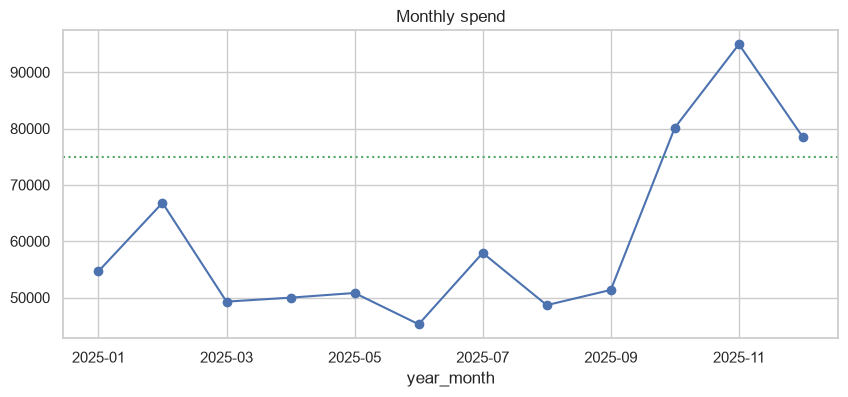

In [12]:
m['total'].plot(marker='o', figsize=(10,4), title='Monthly spend'); plt.axhline(config.MONTHLY_INCOME, color='g', ls=':'); plt.show()

## 5. Spending patterns

In [13]:
analysis.weekday_pattern(df)

,avg_daily_spend
weekday,
Monday,1451.05
Tuesday,1482.19
Wednesday,1632.00
Thursday,1406.20
Friday,1726.33
Saturday,1997.48
Sunday,1772.28


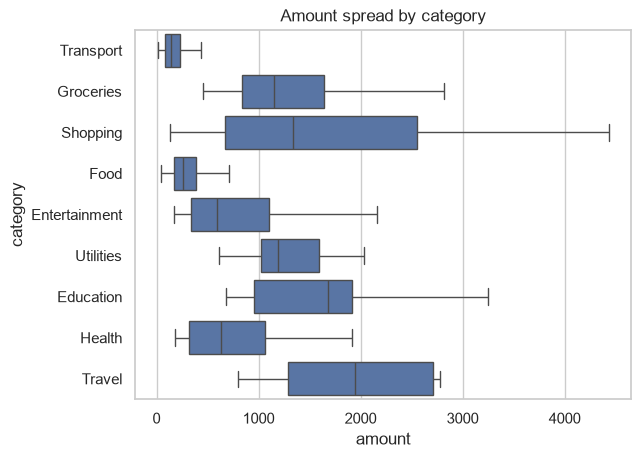

In [14]:
sns.boxplot(data=df[df.category!='Rent'], x='amount', y='category', showfliers=False); plt.title('Amount spread by category'); plt.show()

In [15]:
analysis.payment_method_summary(df)

,total,transactions,share_pct
payment_method,,,
UPI,261857.30,449,35.95
Net Banking,191935.14,64,26.35
Credit Card,112696.61,153,15.47
Debit Card,68578.09,112,9.42
Cash,60966.86,115,8.37
Unknown,32303.63,27,4.44


## 6. Budget & overspending

In [16]:
analysis.overspending_report(analysis.budget_vs_actual(df)).head(15)

,year_month,category,budget,actual,variance,utilisation_pct,overspent
0,2025-10,Shopping,6000,21265.59,15265.59,354.4,True
1,2025-11,Food,7500,19974.80,12474.80,266.3,True
2,2025-09,Shopping,6000,16990.72,10990.72,283.2,True
3,2025-11,Travel,4000,14656.82,10656.82,366.4,True
4,2025-12,Groceries,9000,17916.78,8916.78,199.1,True
5,2025-02,Shopping,6000,12747.50,6747.50,212.5,True
6,2025-08,Groceries,9000,15292.69,6292.69,169.9,True
7,2025-12,Food,7500,13354.28,5854.28,178.1,True
8,2025-01,Shopping,6000,11767.85,5767.85,196.1,True
9,2025-10,Food,7500,13257.94,5757.94,176.8,True


## 7. Anomalies (unusually large transactions)

In [17]:
analysis.detect_anomalies(df)

,transaction_id,date,category,description,amount,payment_method,z_score
0,TXN100429,2025-12-13,Food,Lunch,2212.56,Credit Card,8.24
1,TXN100012,2025-04-19,Food,Zomato order,1828.29,Credit Card,6.57
2,TXN100664,2025-07-16,Transport,Metro card,902.90,Cash,5.20
3,TXN100733,2025-05-24,Transport,Metro card,819.72,Debit Card,4.60
4,TXN100765,2025-10-01,Food,Swiggy order,1319.58,Cash,4.37
5,TXN100209,2025-12-21,Transport,Uber,780.33,UPI,4.32
6,TXN100251,2025-12-22,Transport,Fuel,763.39,Cash,4.19
7,TXN100475,2025-11-15,Utilities,Mobile recharge,3361.19,UPI,4.12
8,TXN100151,2025-09-05,Shopping,Electronics,9474.97,Credit Card,4.04
9,TXN100651,2025-09-17,Food,Swiggy order,1159.71,Debit Card,3.67


## Key takeaways
- Rent is the biggest fixed cost; Food & Shopping are the biggest variable ones.
- Oct–Dec (festive season) shows a clear spending spike.
- Weekends cost more than weekdays.
- Several categories regularly exceed budget → targeted cuts recommended.